# Compound Profiling

Maria Bryantseva, October 2026. Unpublished computational study.

Recalculate the recorded results and inspect the figures.

In [1]:
from pathlib import Path
import os, subprocess, sys

if not Path("verify_results.py").is_file():
    if not Path("compound-profiling").is_dir():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/maribrya/compound-profiling.git", "compound-profiling"], check=True)
    os.chdir("compound-profiling")
_ = subprocess.run([sys.executable, "verify_results.py"], check=True)

In [2]:
%matplotlib inline
import json
from pathlib import Path
import matplotlib.pyplot as plt

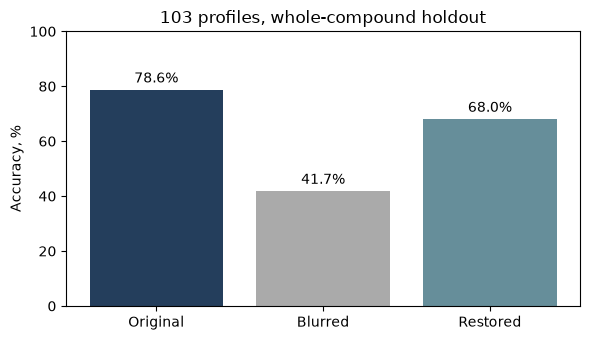

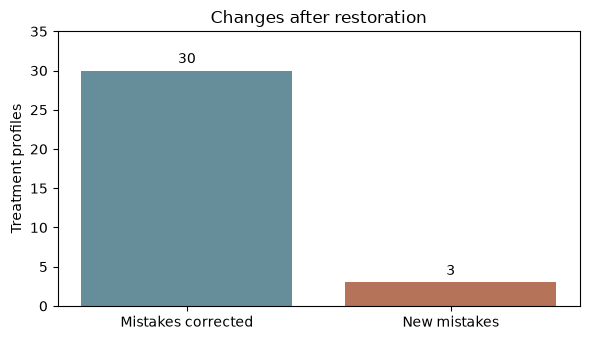

In [3]:
from plot_results import plot_accuracy, plot_transitions
plot_accuracy();
plt.show()
plot_transitions();
plt.show()

In [4]:
import csv
rows = list(csv.DictReader(open("bbbc021/predictions.csv")))
print("Treatment profiles:", len(rows))
for row in rows[:3]:
    print(row)

Treatment profiles: 103
{'compound': 'ALLN', 'concentration': '3.0', 'moa': 'Protein degradation', 'replicates': '3', 'original_prediction': 'Protein degradation', 'blurred_prediction': 'DNA replication', 'restored_prediction': 'Protein degradation', 'original_neighbor_compound': 'proteasome inhibitor I', 'blurred_neighbor_compound': 'camptothecin', 'restored_neighbor_compound': 'proteasome inhibitor I', 'original_neighbor_concentration': '0.1', 'blurred_neighbor_concentration': '0.03', 'restored_neighbor_concentration': '0.1'}
{'compound': 'ALLN', 'concentration': '100.0', 'moa': 'Protein degradation', 'replicates': '3', 'original_prediction': 'Protein synthesis', 'blurred_prediction': 'Cholesterol-lowering', 'restored_prediction': 'Protein synthesis', 'original_neighbor_compound': 'cyclohexamide', 'blurred_neighbor_compound': 'simvastatin', 'restored_neighbor_compound': 'emetine', 'original_neighbor_concentration': '15.0', 'blurred_neighbor_concentration': '2.0', 'restored_neighbor_c

Restoration partially recovers the accuracy lost to blur, but introduces new errors. This pilot holds out compounds, not independent imaging batches.